In [8]:
# ==========================================
# Financial AI - Autoencoder Anomaly Detection
# Cell 1: Imports and Dataset Loading
# ==========================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("TensorFlow Version:", tf.__version__)

# Load dataset
df = pd.read_csv("../dataset/creditcard.csv")

print("Dataset Shape:", df.shape)
print("\nClass Distribution:")
print(df["Class"].value_counts())

print("\nFirst 5 Rows:")
display(df.head())

TensorFlow Version: 2.21.0
Dataset Shape: (284807, 31)

Class Distribution:
Class
0    284315
1       492
Name: count, dtype: int64

First 5 Rows:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [9]:
# ==========================================
# Cell 2: Data Preprocessing
# ==========================================

from sklearn.preprocessing import RobustScaler

# Keep original dataframe safe
df_processed = df.copy()

# Load the same scalers used in our project
amount_scaler = joblib.load("../models/amount_scaler.pkl")
time_scaler = joblib.load("../models/time_scaler.pkl")

# Apply scaling
df_processed["Amount"] = amount_scaler.transform(
    df_processed[["Amount"]]
)

df_processed["Time"] = time_scaler.transform(
    df_processed[["Time"]]
)

# Separate features and target
X = df_processed.drop("Class", axis=1)
y = df_processed["Class"]

# Normal and fraud transactions
X_normal = X[y == 0]
X_fraud = X[y == 1]

print("Total transactions :", len(X))
print("Normal transactions:", len(X_normal))
print("Fraud transactions :", len(X_fraud))
print("Number of features :", X.shape[1])

Total transactions : 284807
Normal transactions: 284315
Fraud transactions : 492
Number of features : 30


In [10]:
import sys

print(sys.executable)

c:\Users\Ritik\OneDrive\Desktop\Financial-Anomaly-Detection\.venv\Scripts\python.exe


In [11]:
# ==========================================
# Cell 3: Build Autoencoder
# ==========================================

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense

# Number of input features
input_dim = X_normal.shape[1]

# Create Autoencoder
autoencoder = Sequential([
    Input(shape=(input_dim,)),

    # Encoder
    Dense(16, activation="relu"),
    Dense(8, activation="relu"),

    # Decoder
    Dense(16, activation="relu"),
    Dense(input_dim, activation="linear")
])

# Compile model
autoencoder.compile(
    optimizer="adam",
    loss="mse"
)

# Display architecture
autoencoder.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 30)             │           510 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,286 (5.02 KB)

 Trainable params: 1,286 (5.02 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
# ==========================================
# Cell 4: Train Autoencoder
# ==========================================

from tensorflow.keras.callbacks import EarlyStopping

# Convert normal data to NumPy array
X_normal_array = X_normal.values.astype("float32")

print("Training data shape:", X_normal_array.shape)

# Early stopping prevents unnecessary training
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

# Train Autoencoder
history = autoencoder.fit(
    X_normal_array,
    X_normal_array,
    epochs=50,
    batch_size=256,
    validation_split=0.2,
    shuffle=True,
    callbacks=[early_stopping],
    verbose=1
)

print("\n✅ Autoencoder training completed!")

Training data shape: (284315, 30)
Epoch 1/50
889/889 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - loss: 0.7688 - val_loss: 0.5198
Epoch 2/50
889/889 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.4478 - val_loss: 0.4187
Epoch 3/50
889/889 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3835 - val_loss: 0.3892
Epoch 4/50
889/889 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3558 - val_loss: 0.3569
Epoch 5/50
889/889 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3373 - val_loss: 0.3433
Epoch 6/50
889/889 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3217 - val_loss: 0.3246
Epoch 7/50
889/889 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.3072 - val_loss: 0.3104
Epoch 8/50
889/889 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.2934 - val_loss: 0.2980
Epoch 9/50
889/889 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.2849 - val_loss: 0.2899
Epoch 10/50
889/889 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.2798 - val_loss: 0.2869
Epoch 11/50
889/889 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - loss: 0.2759 - val_loss: 0.2863
Epoch 12/50
889/88

In [13]:
# ==========================================
# Cell 5: Calculate Reconstruction Error
# ==========================================

# Reconstruct all transactions
X_all_array = X.values.astype("float32")

X_reconstructed = autoencoder.predict(
    X_all_array,
    batch_size=256,
    verbose=1
)

# Calculate reconstruction error for every transaction
reconstruction_error = np.mean(
    np.square(X_all_array - X_reconstructed),
    axis=1
)

print("Reconstruction error calculated!")
print("Shape:", reconstruction_error.shape)

print("\nNormal transaction error:")
print(
    reconstruction_error[y.values == 0].mean()
)

print("\nFraud transaction error:")
print(
    reconstruction_error[y.values == 1].mean()
)

1113/1113 ━━━━━━━━━━━━━━━━━━━━ 1s 700us/step
Reconstruction error calculated!
Shape: (284807,)

Normal transaction error:
0.25443012

Fraud transaction error:
6.7592564


In [14]:
# ==========================================
# Cell 6: Autoencoder Threshold Tuning
# ==========================================

from sklearn.metrics import precision_score, recall_score, f1_score

# Test multiple thresholds
percentiles = np.arange(90, 100, 0.5)

ae_threshold_results = []

for percentile in percentiles:

    # Threshold based on normal transaction errors
    threshold = np.percentile(
        reconstruction_error[y.values == 0],
        percentile
    )

    # Anomaly prediction
    predictions = (
        reconstruction_error >= threshold
    ).astype(int)

    precision = precision_score(
        y,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        y,
        predictions,
        zero_division=0
    )

    ae_threshold_results.append({
        "percentile": percentile,
        "threshold": threshold,
        "precision": precision,
        "recall": recall,
        "f1": f1
    })

# Create DataFrame
ae_threshold_df = pd.DataFrame(ae_threshold_results)

# Best threshold based on F1
best_ae_row = ae_threshold_df.loc[
    ae_threshold_df["f1"].idxmax()
]

best_ae_threshold = best_ae_row["threshold"]

print("Best Autoencoder Threshold")
print("--------------------------------")
print("Percentile :", best_ae_row["percentile"])
print("Threshold  :", best_ae_threshold)
print("Precision  :", best_ae_row["precision"])
print("Recall     :", best_ae_row["recall"])
print("F1 Score   :", best_ae_row["f1"])

Best Autoencoder Threshold
--------------------------------
Percentile : 99.5
Threshold  : 2.0837817811965933
Precision  : 0.18369690011481057
Recall     : 0.6504065040650406
F1 Score   : 0.2864816472694718


In [15]:
# ==========================================
# Cell 7: Final Autoencoder Evaluation
# ==========================================

from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Use the best threshold found in Cell 6
ae_predictions = (
    reconstruction_error >= best_ae_threshold
).astype(int)

# Calculate confusion matrix
cm_ae = confusion_matrix(y, ae_predictions)

TN, FP, FN, TP = cm_ae.ravel()

# Final metrics
ae_precision = precision_score(
    y,
    ae_predictions,
    zero_division=0
)

ae_recall = recall_score(
    y,
    ae_predictions,
    zero_division=0
)

ae_f1 = f1_score(
    y,
    ae_predictions,
    zero_division=0
)

print("==========================================")
print("      AUTOENCODER FINAL EVALUATION")
print("==========================================")

print("\nConfusion Matrix:")
print(cm_ae)

print("\nConfusion Matrix Details:")
print("True Negatives  (TN):", TN)
print("False Positives (FP):", FP)
print("False Negatives (FN):", FN)
print("True Positives  (TP):", TP)

print("\nPerformance:")
print("Precision:", ae_precision)
print("Recall   :", ae_recall)
print("F1 Score :", ae_f1)

print("\nClassification Report:")
print(
    classification_report(
        y,
        ae_predictions,
        target_names=["Normal", "Fraud"],
        zero_division=0
    )
)

      AUTOENCODER FINAL EVALUATION

Confusion Matrix:
[[282893   1422]
 [   172    320]]

Confusion Matrix Details:
True Negatives  (TN): 282893
False Positives (FP): 1422
False Negatives (FN): 172
True Positives  (TP): 320

Performance:
Precision: 0.18369690011481057
Recall   : 0.6504065040650406
F1 Score : 0.2864816472694718

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      0.99      1.00    284315
       Fraud       0.18      0.65      0.29       492

    accuracy                           0.99    284807
   macro avg       0.59      0.82      0.64    284807
weighted avg       1.00      0.99      1.00    284807



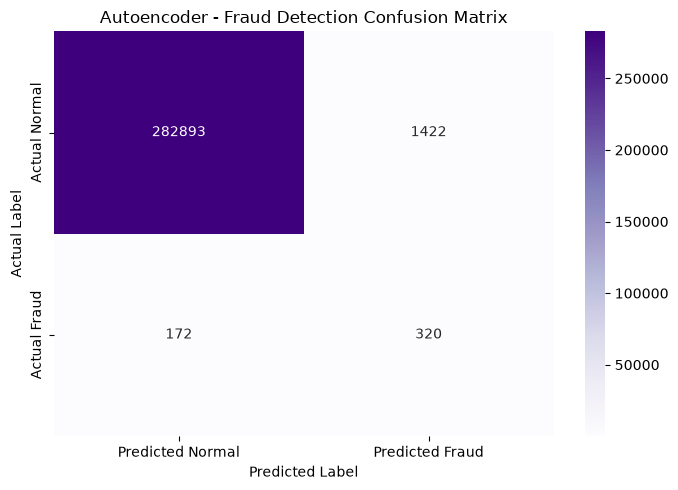

In [16]:
# ==========================================
# Cell 8: Autoencoder Confusion Matrix
# ==========================================

import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_ae,
    annot=True,
    fmt="d",
    cmap="Purples",
    xticklabels=["Predicted Normal", "Predicted Fraud"],
    yticklabels=["Actual Normal", "Actual Fraud"]
)

plt.title("Autoencoder - Fraud Detection Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()

In [17]:
# ==========================================
# Cell 9: Save Autoencoder Model & Results
# ==========================================

import os
import joblib
import pandas as pd

# Make sure folders exist
os.makedirs("../models", exist_ok=True)
os.makedirs("../results", exist_ok=True)

# 1. Save Autoencoder model
autoencoder.save("../models/autoencoder.keras")

# 2. Save best threshold
joblib.dump(
    best_ae_threshold,
    "../models/autoencoder_threshold.pkl"
)

# 3. Save confusion matrix
ae_cm_df = pd.DataFrame(
    cm_ae,
    index=["Actual Normal", "Actual Fraud"],
    columns=["Predicted Normal", "Predicted Fraud"]
)

ae_cm_df.to_csv(
    "../results/autoencoder_confusion_matrix.csv"
)

# 4. Save final metrics
ae_metrics_df = pd.DataFrame([{
    "Model": "Autoencoder",
    "Threshold": best_ae_threshold,
    "Precision": ae_precision,
    "Recall": ae_recall,
    "F1": ae_f1,
    "True_Negative": TN,
    "False_Positive": FP,
    "False_Negative": FN,
    "True_Positive": TP
}])

ae_metrics_df.to_csv(
    "../results/autoencoder_metrics.csv",
    index=False
)

# 5. Save threshold tuning results
ae_threshold_df.to_csv(
    "../results/autoencoder_threshold_results.csv",
    index=False
)

print("==========================================")
print("   AUTOENCODER FILES SAVED SUCCESSFULLY")
print("==========================================")

print("\nModel:")
print("../models/autoencoder.keras")

print("\nThreshold:")
print("../models/autoencoder_threshold.pkl")

print("\nResults:")
print("../results/autoencoder_confusion_matrix.csv")
print("../results/autoencoder_metrics.csv")
print("../results/autoencoder_threshold_results.csv")

   AUTOENCODER FILES SAVED SUCCESSFULLY

Model:
../models/autoencoder.keras

Threshold:
../models/autoencoder_threshold.pkl

Results:
../results/autoencoder_confusion_matrix.csv
../results/autoencoder_metrics.csv
../results/autoencoder_threshold_results.csv


In [18]:
# ==========================================
# Cell 10: Final Model Comparison
# ==========================================

import pandas as pd

# Isolation Forest results
if_precision = 0.137544
if_recall = 0.398374
if_f1 = 0.204486

# LOF results
lof_precision = 0.010300
lof_recall = 0.247967
lof_f1 = 0.019778

# Autoencoder results
ae_precision = float(ae_precision)
ae_recall = float(ae_recall)
ae_f1 = float(ae_f1)

# Create comparison table
model_comparison = pd.DataFrame({
    "Model": [
        "Isolation Forest",
        "LOF",
        "Autoencoder"
    ],
    "Precision": [
        if_precision,
        lof_precision,
        ae_precision
    ],
    "Recall": [
        if_recall,
        lof_recall,
        ae_recall
    ],
    "F1 Score": [
        if_f1,
        lof_f1,
        ae_f1
    ]
})

# Sort by F1 score
model_comparison = model_comparison.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

print("==========================================")
print("       FINAL MODEL COMPARISON")
print("==========================================")

display(model_comparison)

# Save comparison
model_comparison.to_csv(
    "../results/final_model_comparison.csv",
    index=False
)

print("\n✅ Comparison saved successfully!")
print("../results/final_model_comparison.csv")

       FINAL MODEL COMPARISON


,Model,Precision,Recall,F1 Score
0,Autoencoder,0.183697,0.650407,0.286482
1,Isolation Forest,0.137544,0.398374,0.204486
2,LOF,0.010300,0.247967,0.019778



✅ Comparison saved successfully!
../results/final_model_comparison.csv


In [19]:
# ==========================================
# Recovery Cell: Reload Models
# ==========================================

import joblib

isolation_forest = joblib.load(
    "../models/isolation_forest.pkl"
)

lof = joblib.load(
    "../models/lof.pkl"
)

best_threshold = joblib.load(
    "../models/isolation_forest_threshold.pkl"
)

print("✅ Isolation Forest loaded")
print("✅ LOF loaded")
print("✅ Isolation Forest threshold loaded")

✅ Isolation Forest loaded
✅ LOF loaded
✅ Isolation Forest threshold loaded


In [20]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (284807, 30)
y shape: (284807,)


In [21]:
# ==========================================
# Cell 11: Prepare Ensemble Scores
# ==========================================

import numpy as np
import pandas as pd

print("Preparing anomaly scores for ensemble...")

# ------------------------------------------
# 1. Isolation Forest score
# ------------------------------------------

if_scores = -isolation_forest.decision_function(X)

print("Isolation Forest scores ready.")


# ------------------------------------------
# 2. LOF score
# ------------------------------------------

lof_scores = -lof.decision_function(X)

print("LOF scores ready.")


# ------------------------------------------
# 3. Autoencoder reconstruction error
# ------------------------------------------

ae_scores = reconstruction_error.copy()

print("Autoencoder scores ready.")


# ------------------------------------------
# Check score ranges
# ------------------------------------------

print("\n==========================================")
print("RAW SCORE RANGES")
print("==========================================")

print("\nIsolation Forest:")
print("Min:", if_scores.min())
print("Max:", if_scores.max())

print("\nLOF:")
print("Min:", lof_scores.min())
print("Max:", lof_scores.max())

print("\nAutoencoder:")
print("Min:", ae_scores.min())
print("Max:", ae_scores.max())

Preparing anomaly scores for ensemble...
Isolation Forest scores ready.


c:\Users\Ritik\OneDrive\Desktop\Financial-Anomaly-Detection\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LocalOutlierFactor was fitted with feature names
  warnings.warn(


LOF scores ready.
Autoencoder scores ready.

RAW SCORE RANGES

Isolation Forest:
Min: -0.1544662662647761
Max: 0.2608907332831709

LOF:
Min: -0.6162679792529524
Max: 3008.648898140156

Autoencoder:
Min: 0.0054431413
Max: 101.03141


In [22]:
# ==========================================
# Cell 12: Normalize Anomaly Scores
# ==========================================

from scipy.stats import rankdata

# Convert each model's raw score into percentile/rank score
# Higher value = more anomalous

if_rank = rankdata(if_scores, method="average") / len(if_scores)

lof_rank = rankdata(lof_scores, method="average") / len(lof_scores)

ae_rank = rankdata(ae_scores, method="average") / len(ae_scores)


print("==========================================")
print("NORMALIZED SCORE RANGES")
print("==========================================")

print("\nIsolation Forest:")
print("Min:", if_rank.min())
print("Max:", if_rank.max())

print("\nLOF:")
print("Min:", lof_rank.min())
print("Max:", lof_rank.max())

print("\nAutoencoder:")
print("Min:", ae_rank.min())
print("Max:", ae_rank.max())


# Create a dataframe for inspection
ensemble_scores_df = pd.DataFrame({
    "IF_Rank": if_rank,
    "LOF_Rank": lof_rank,
    "AE_Rank": ae_rank,
    "Actual_Class": y.values
})

print("\nFirst 5 rows:")
display(ensemble_scores_df.head())

NORMALIZED SCORE RANGES

Isolation Forest:
Min: 3.5111496557317763e-06
Max: 1.0

LOF:
Min: 5.266724483597665e-06
Max: 1.0

Autoencoder:
Min: 3.5111495e-06
Max: 1.0

First 5 rows:


,IF_Rank,LOF_Rank,AE_Rank,Actual_Class
0,0.619170,0.591636,0.269509,0
1,0.184988,0.954179,0.034501,0
2,0.924682,0.747942,0.961690,0
3,0.699786,0.371100,0.829200,0
4,0.498671,0.820956,0.222312,0


In [23]:
# ==========================================
# Cell 13: Create Ensemble Anomaly Score
# ==========================================

# Model weights
IF_WEIGHT = 0.40
LOF_WEIGHT = 0.20
AE_WEIGHT = 0.40

# Calculate weighted ensemble score
ensemble_score = (
    IF_WEIGHT * if_rank
    + LOF_WEIGHT * lof_rank
    + AE_WEIGHT * ae_rank
)

print("==========================================")
print("       ENSEMBLE SCORE CREATED")
print("==========================================")

print("Isolation Forest Weight :", IF_WEIGHT)
print("LOF Weight              :", LOF_WEIGHT)
print("Autoencoder Weight      :", AE_WEIGHT)

print("\nEnsemble Score Range:")
print("Min:", ensemble_score.min())
print("Max:", ensemble_score.max())
print("Mean:", ensemble_score.mean())

# Create dataframe
ensemble_df = pd.DataFrame({
    "IF_Rank": if_rank,
    "LOF_Rank": lof_rank,
    "AE_Rank": ae_rank,
    "Ensemble_Score": ensemble_score,
    "Actual_Class": y.values
})

print("\nFirst 5 Ensemble Scores:")
display(ensemble_df.head())

       ENSEMBLE SCORE CREATED
Isolation Forest Weight : 0.4
LOF Weight              : 0.2
Autoencoder Weight      : 0.4

Ensemble Score Range:
Min: 0.003361223572251734
Max: 0.9997661448432006
Mean: 0.5000017590441485

First 5 Ensemble Scores:


,IF_Rank,LOF_Rank,AE_Rank,Ensemble_Score,Actual_Class
0,0.619170,0.591636,0.269509,0.473799,0
1,0.184988,0.954179,0.034501,0.278631,0
2,0.924682,0.747942,0.961690,0.904137,0
3,0.699786,0.371100,0.829200,0.685815,0
4,0.498671,0.820956,0.222312,0.452584,0


In [32]:
# ==========================================
# Cell 14: Ensemble Threshold Tuning
# ==========================================

from sklearn.metrics import precision_score, recall_score, f1_score

# Test thresholds based on percentiles of normal transactions
percentiles = np.arange(90, 100, 0.5)

ensemble_threshold_results = []

# Only normal transactions are used to determine thresholds
normal_ensemble_scores = ensemble_score[y.values == 0]

for percentile in percentiles:

    threshold = np.percentile(
        normal_ensemble_scores,
        percentile
    )

    # Flag transactions above threshold as anomalies
    predictions = (
        ensemble_score >= threshold
    ).astype(int)

    precision = precision_score(
        y,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        y,
        predictions,
        zero_division=0
    )

    ensemble_threshold_results.append({
        "percentile": percentile,
        "threshold": threshold,
        "precision": precision,
        "recall": recall,
        "f1": f1
    })


# Convert to DataFrame
ensemble_threshold_df = pd.DataFrame(
    ensemble_threshold_results
)

# Find best threshold based on F1
best_ensemble_row = ensemble_threshold_df.loc[
    ensemble_threshold_df["f1"].idxmax()
]

best_ensemble_threshold = (
    best_ensemble_row["threshold"]
)

print("==========================================")
print("      BEST ENSEMBLE THRESHOLD")
print("==========================================")

print(
    "Percentile :",
    best_ensemble_row["percentile"]
)

print(
    "Threshold  :",
    best_ensemble_threshold
)

print(
    "Precision  :",
    best_ensemble_row["precision"]
)

print(
    "Recall     :",
    best_ensemble_row["recall"]
)

print(
    "F1 Score   :",
    best_ensemble_row["f1"]
)

      BEST ENSEMBLE THRESHOLD
Percentile : 99.5
Threshold  : 0.9641422697680397
Precision  : 0.1
Recall     : 0.32113821138211385
F1 Score   : 0.1525096525096525


In [25]:
# ==========================================
# Cell 15: Ensemble Weight Optimization
# ==========================================

from sklearn.metrics import precision_score, recall_score, f1_score
import numpy as np
import pandas as pd

weight_results = []

# Test weights in steps of 10%
for ae_weight in np.arange(0.0, 1.01, 0.1):

    for if_weight in np.arange(0.0, 1.01 - ae_weight, 0.1):

        lof_weight = round(
            1.0 - ae_weight - if_weight,
            10
        )

        if lof_weight < 0:
            continue

        # Create ensemble score
        test_ensemble_score = (
            if_weight * if_rank
            + lof_weight * lof_rank
            + ae_weight * ae_rank
        )

        # Thresholds based only on normal transactions
        normal_scores = test_ensemble_score[
            y.values == 0
        ]

        best_f1 = -1
        best_precision = 0
        best_recall = 0
        best_threshold = 0
        best_percentile = 0

        for percentile in np.arange(90, 100, 0.5):

            threshold = np.percentile(
                normal_scores,
                percentile
            )

            predictions = (
                test_ensemble_score >= threshold
            ).astype(int)

            precision = precision_score(
                y,
                predictions,
                zero_division=0
            )

            recall = recall_score(
                y,
                predictions,
                zero_division=0
            )

            f1 = f1_score(
                y,
                predictions,
                zero_division=0
            )

            if f1 > best_f1:
                best_f1 = f1
                best_precision = precision
                best_recall = recall
                best_threshold = threshold
                best_percentile = percentile

        weight_results.append({
            "IF_Weight": if_weight,
            "LOF_Weight": lof_weight,
            "AE_Weight": ae_weight,
            "Best_Percentile": best_percentile,
            "Best_Threshold": best_threshold,
            "Precision": best_precision,
            "Recall": best_recall,
            "F1": best_f1
        })


# Convert results to DataFrame
weight_results_df = pd.DataFrame(weight_results)

# Sort by F1
weight_results_df = weight_results_df.sort_values(
    by="F1",
    ascending=False
).reset_index(drop=True)

print("==========================================")
print("     ENSEMBLE WEIGHT OPTIMIZATION")
print("==========================================")

print("\nTop 10 configurations:")
display(
    weight_results_df.head(10)
)

# Best configuration
best_weight_row = weight_results_df.iloc[0]

print("\n==========================================")
print("       BEST ENSEMBLE CONFIGURATION")
print("==========================================")

print(
    "Isolation Forest Weight :",
    best_weight_row["IF_Weight"]
)

print(
    "LOF Weight              :",
    best_weight_row["LOF_Weight"]
)

print(
    "Autoencoder Weight      :",
    best_weight_row["AE_Weight"]
)

print(
    "Threshold Percentile    :",
    best_weight_row["Best_Percentile"]
)

print(
    "Threshold               :",
    best_weight_row["Best_Threshold"]
)

print(
    "Precision               :",
    best_weight_row["Precision"]
)

print(
    "Recall                  :",
    best_weight_row["Recall"]
)

print(
    "F1 Score                :",
    best_weight_row["F1"]
)

     ENSEMBLE WEIGHT OPTIMIZATION

Top 10 configurations:


,IF_Weight,LOF_Weight,AE_Weight,Best_Percentile,Best_Threshold,Precision,Recall,F1
0,0.1,-0.0,0.9,99.5,0.992872,0.183697,0.650407,0.286482
1,0.0,0.0,1.0,99.5,0.993885,0.183697,0.650407,0.286482
2,0.2,-0.0,0.8,99.5,0.992183,0.180876,0.638211,0.281867
3,0.3,-0.0,0.7,99.5,0.991642,0.179458,0.632114,0.279551
4,0.4,-0.0,0.6,99.5,0.991221,0.174216,0.609756,0.271003
5,0.5,0.0,0.5,99.5,0.991061,0.172293,0.601626,0.267873
6,0.6,-0.0,0.4,99.5,0.990991,0.167447,0.581301,0.260000
7,0.7,-0.0,0.3,99.5,0.991023,0.159574,0.548780,0.247253
8,0.8,0.0,0.2,99.5,0.991359,0.153983,0.526423,0.238270
9,0.9,0.0,0.1,99.5,0.992195,0.145433,0.491870,0.224490



       BEST ENSEMBLE CONFIGURATION
Isolation Forest Weight : 0.1
LOF Weight              : -0.0
Autoencoder Weight      : 0.9
Threshold Percentile    : 99.5
Threshold               : 0.9928722663345458
Precision               : 0.18369690011481057
Recall                  : 0.6504065040650406
F1 Score                : 0.2864816472694718


In [26]:
# ==========================================
# Cell 16: Autoencoder Feature Explanation
# ==========================================

# Calculate feature-wise reconstruction error
feature_errors = np.square(
    X_all_array - X_reconstructed
)

feature_names = X.columns.tolist()

# Average error across all transactions
mean_feature_error = feature_errors.mean(axis=0)

feature_error_df = pd.DataFrame({
    "Feature": feature_names,
    "Mean_Reconstruction_Error": mean_feature_error
})

# Sort highest error first
feature_error_df = feature_error_df.sort_values(
    by="Mean_Reconstruction_Error",
    ascending=False
).reset_index(drop=True)

print("==========================================")
print("  AUTOENCODER FEATURE ERROR ANALYSIS")
print("==========================================")

display(
    feature_error_df.head(15)
)

  AUTOENCODER FEATURE ERROR ANALYSIS


,Feature,Mean_Reconstruction_Error
0,V15,0.794227
1,V16,0.675700
2,V18,0.672840
3,V19,0.644724
4,V22,0.519868
5,V21,0.513174
6,V14,0.468485
7,V17,0.455319
8,V23,0.389644
9,V24,0.367957


In [27]:
# ==========================================
# Cell 17: Individual Transaction Explanation
# ==========================================

# Choose a transaction to investigate
transaction_index = 0

# Original input
original_transaction = X_all_array[transaction_index]

# Reconstructed input
reconstructed_transaction = X_reconstructed[transaction_index]

# Feature-wise reconstruction error
transaction_feature_error = np.square(
    original_transaction - reconstructed_transaction
)

# Create explanation table
transaction_explanation = pd.DataFrame({
    "Feature": feature_names,
    "Original_Value": original_transaction,
    "Reconstructed_Value": reconstructed_transaction,
    "Reconstruction_Error": transaction_feature_error
})

# Sort by highest error
transaction_explanation = transaction_explanation.sort_values(
    by="Reconstruction_Error",
    ascending=False
).reset_index(drop=True)

print("==========================================")
print("   INDIVIDUAL TRANSACTION EXPLANATION")
print("==========================================")

print("Transaction Index:", transaction_index)
print(
    "Overall Reconstruction Error:",
    reconstruction_error[transaction_index]
)

print("\nTop 10 contributing features:")

display(
    transaction_explanation.head(10)
)

   INDIVIDUAL TRANSACTION EXPLANATION
Transaction Index: 0
Overall Reconstruction Error: 0.1084811

Top 10 contributing features:


,Feature,Original_Value,Reconstructed_Value,Reconstruction_Error
0,V15,1.468177,-0.047599,2.297577
1,Time,-0.994983,-0.386680,0.370034
2,V12,-0.617801,-0.288192,0.108642
3,V19,0.403993,0.117453,0.082105
4,V17,0.207971,-0.060464,0.072057
5,V22,0.277838,0.038915,0.057084
6,V25,0.128539,-0.094236,0.049629
7,V26,-0.189115,0.024608,0.045677
8,V21,-0.018307,0.150828,0.028606
9,V16,-0.470401,-0.311833,0.025144


In [28]:
# ==========================================
# Cell 18: Investigate Highest-Risk Transaction
# ==========================================

# Find transaction with highest reconstruction error
highest_risk_index = np.argmax(reconstruction_error)

highest_risk_score = reconstruction_error[
    highest_risk_index
]

# Get actual class
actual_class = y.iloc[highest_risk_index]

# Get prediction
predicted_class = ae_predictions[
    highest_risk_index
]

print("==========================================")
print("     HIGHEST-RISK TRANSACTION")
print("==========================================")

print("Transaction Index :", highest_risk_index)

print("Actual Class      :", actual_class)

print("Predicted Class   :", predicted_class)

print("Reconstruction Error :", highest_risk_score)

print("Autoencoder Threshold :", best_ae_threshold)

if predicted_class == 1:
    print("\n🚨 AUTOENCODER FLAGGED THIS TRANSACTION")
else:
    print("\n✅ AUTOENCODER CONSIDERED THIS NORMAL")


# ------------------------------------------
# Feature-level explanation
# ------------------------------------------

original_high_risk = X_all_array[
    highest_risk_index
]

reconstructed_high_risk = X_reconstructed[
    highest_risk_index
]

high_risk_feature_error = np.square(
    original_high_risk - reconstructed_high_risk
)

high_risk_explanation = pd.DataFrame({
    "Feature": feature_names,
    "Original_Value": original_high_risk,
    "Reconstructed_Value": reconstructed_high_risk,
    "Reconstruction_Error": high_risk_feature_error
})

high_risk_explanation = high_risk_explanation.sort_values(
    by="Reconstruction_Error",
    ascending=False
).reset_index(drop=True)

print("\n==========================================")
print("       TOP UNUSUAL FEATURES")
print("==========================================")

display(
    high_risk_explanation.head(10)
)

     HIGHEST-RISK TRANSACTION
Transaction Index : 154684
Actual Class      : 1
Predicted Class   : 1
Reconstruction Error : 101.03141
Autoencoder Threshold : 2.0837817811965933

🚨 AUTOENCODER FLAGGED THIS TRANSACTION

       TOP UNUSUAL FEATURES


,Feature,Original_Value,Reconstructed_Value,Reconstruction_Error
0,V21,-22.797604,1.716990,600.965271
1,V5,-18.983812,3.802991,519.238342
2,V6,6.474114,-11.203653,312.503510
3,Amount,-0.307273,-16.133181,250.459351
4,V10,-24.588263,-10.718843,192.360779
5,V17,-13.032785,-0.656774,153.165665
6,V4,11.845013,-0.508456,152.608200
7,V3,-27.855812,-39.335972,131.794067
8,V2,22.057730,11.531393,110.803764
9,V20,11.059004,2.054333,81.084099


In [29]:
# ==========================================
# Cell 19: Verify Reconstruction Error
# ==========================================

# Recalculate feature-wise errors
check_feature_errors = np.square(
    X_all_array[highest_risk_index]
    - X_reconstructed[highest_risk_index]
)

# Calculate mean and sum
calculated_mean_error = np.mean(check_feature_errors)
calculated_total_error = np.sum(check_feature_errors)

# Compare with stored reconstruction error
stored_error = reconstruction_error[highest_risk_index]

print("==========================================")
print("    RECONSTRUCTION ERROR VERIFICATION")
print("==========================================")

print("Transaction Index:", highest_risk_index)
print("Stored Reconstruction Error:", stored_error)
print("Calculated Mean Error:", calculated_mean_error)
print("Calculated Total Error:", calculated_total_error)

print("\nDifference:", abs(stored_error - calculated_mean_error))

if np.isclose(stored_error, calculated_mean_error, rtol=1e-4):
    print("\n✅ Reconstruction errors match.")
else:
    print("\n⚠️ Reconstruction errors do not match.")
    print("Please verify that the model, predictions, and arrays")
    print("belong to the same notebook execution.")

    RECONSTRUCTION ERROR VERIFICATION
Transaction Index: 154684
Stored Reconstruction Error: 101.03141
Calculated Mean Error: 101.03141
Calculated Total Error: 3030.9424

Difference: 0.0

✅ Reconstruction errors match.


In [30]:
# ==========================================
# Fix: Reinitialize Required Variables
# ==========================================

import numpy as np
import pandas as pd

# Recreate the input array
X_all_array = X.values.astype("float32")

# Recalculate reconstructed values
X_reconstructed = autoencoder.predict(
    X_all_array,
    batch_size=256,
    verbose=1
)

# Recalculate reconstruction errors
reconstruction_error = np.mean(
    np.square(X_all_array - X_reconstructed),
    axis=1
)

# Recreate predictions using the existing threshold
ae_predictions = (
    reconstruction_error >= best_ae_threshold
).astype(int)

# Recalculate the highest-risk transaction
highest_risk_index = np.argmax(reconstruction_error)

print("✅ Required variables recreated!")
print("Dataset shape:", X_all_array.shape)
print("Reconstruction shape:", X_reconstructed.shape)
print("Highest-risk transaction:", highest_risk_index)

1113/1113 ━━━━━━━━━━━━━━━━━━━━ 1s 675us/step
✅ Required variables recreated!
Dataset shape: (284807, 30)
Reconstruction shape: (284807, 30)
Highest-risk transaction: 154684


In [31]:
# ==========================================
# Cell 20: Verify Top Unusual Features
# ==========================================

check_original = X_all_array[highest_risk_index]

check_reconstructed = X_reconstructed[highest_risk_index]

check_errors = np.square(
    check_original - check_reconstructed
)

check_feature_df = pd.DataFrame({
    "Feature": feature_names,
    "Original_Value": check_original,
    "Reconstructed_Value": check_reconstructed,
    "Reconstruction_Error": check_errors
})

check_feature_df = check_feature_df.sort_values(
    by="Reconstruction_Error",
    ascending=False
).reset_index(drop=True)

print("Transaction Index:", highest_risk_index)

print("Mean Reconstruction Error:", check_errors.mean())

print("\nTop 10 Unusual Features:")

display(check_feature_df.head(10))

Transaction Index: 154684
Mean Reconstruction Error: 101.03141

Top 10 Unusual Features:


,Feature,Original_Value,Reconstructed_Value,Reconstruction_Error
0,V21,-22.797604,1.716990,600.965271
1,V5,-18.983812,3.802991,519.238342
2,V6,6.474114,-11.203653,312.503510
3,Amount,-0.307273,-16.133181,250.459351
4,V10,-24.588263,-10.718843,192.360779
5,V17,-13.032785,-0.656774,153.165665
6,V4,11.845013,-0.508456,152.608200
7,V3,-27.855812,-39.335972,131.794067
8,V2,22.057730,11.531393,110.803764
9,V20,11.059004,2.054333,81.084099


In [33]:
# ==========================================
# Cell 21: Verify Highest-Risk Transaction
# ==========================================

idx = highest_risk_index

feature_errors = np.square(
    X_all_array[idx] - X_reconstructed[idx]
)

mean_error = feature_errors.mean()
total_error = feature_errors.sum()

print("=" * 45)
print("       TRANSACTION VERIFICATION")
print("=" * 45)

print("Transaction Index:", idx)
print("Actual Class:", y.iloc[idx])
print("Predicted Class:", ae_predictions[idx])
print("Stored Reconstruction Error:", reconstruction_error[idx])
print("Recalculated Mean Error:", mean_error)
print("Total Feature Error:", total_error)
print("Mean of 30 Feature Errors:", total_error / len(feature_errors))

print("\nError matches:",
      np.isclose(reconstruction_error[idx], mean_error, rtol=1e-4))

print("Highest-risk index matches:",
      idx == np.argmax(reconstruction_error))

       TRANSACTION VERIFICATION
Transaction Index: 154684
Actual Class: 1
Predicted Class: 1
Stored Reconstruction Error: 101.03141
Recalculated Mean Error: 101.03141
Total Feature Error: 3030.9424
Mean of 30 Feature Errors: 101.03141

Error matches: True
Highest-risk index matches: True
